# Adversarial Search: Solving Tic-Tac-Toe with Heuristic Alpha-Beta Tree Search

## Introduction 

Multiplayer games can be implemented as:
1. Nondeterministic actions: The opponent is seen as part of an environment with nondeterministic actions. Non-determinism is the result of the unknown opponent's moves. 
2. Optimal Decisions: Minimax search (search complete game tree) and alpha-beta pruning.
3. __Heuristic Alpha-Beta Tree Search:__ Cut off tree search and use heuristic to estimate state value. 
4. Monte Carlo Tree search: Simulate playouts to estimate state value. 

Here we will implement search for Tic-Tac-Toe (see [rules](https://en.wikipedia.org/wiki/Tic-tac-toe)). The game is a __zero-sum game__: Win by x results in +1, win by o in -1 and a tie has a value of 0. Max plays x and tries to maximize the outcome while Min plays o and tries to minimize the outcome.   

We will implement
* Heuristic Alpha-Beta Tree Search

The algorithms search the game tree and we could return a conditional plan (or partial plan if cut offs are used), but the implementation here only identifies and returns the optimal next move.

The code for the basic functions used for search are implemented in [tictactoe.py](tictactoe.py).

In [1]:
# download if missing
import urllib.request
import os

def download(file, base_url):
    if not os.path.exists(file):
        urllib.request.urlretrieve(base_url + file, file)

download("tictactoe.py", ".")

In [2]:
from tictactoe import empty_board, actions, result, terminal, utility, other, show_board
from tictactoe import random_player, play 

# Heuristic Alpha-Beta Tree Search

See AIMA page 156ff. 


## Heuristic Evaluation Function

In [3]:
import numpy as np

def eval_fun(state, player = 'x'):
    """heuristic for utility of state. Returns score for a node:
    1. For terminal states it returns the utility. 
    2. For non-terminal states, it calculates a weighted linear function using features of the state. 
    The features we look at are 2 in a row/col/diagonal where the 3rd square is empty. We assume that
    the more of these positions we have, the higher the chance of winning.
    We need to be careful that the utility of the heuristic stays between [-1,1]. 
    Note that the largest possible number of these positions is 2. I weigh the count by 0.4, 
    guaranteeing that is in the needed range.
    
    Function Returns: heuristic value, terminal?"""
    
    # terminal state?
    u = utility(state, player)
    if u is not None: return u, True
      
    score = 0
    board = np.array(state).reshape((3,3))
    diagonals = np.array([[board[i][i] for i in range(len(board))], 
                          [board[i][len(board)-i-1] for i in range(len(board))]])
    
    for a_board in [board, np.transpose(board), diagonals]:
        for row in a_board:
            if sum(row == player) == 2 and any(row ==' '): score += .4
            if sum(row == other(player)) == 2 and any(row ==' '): score -= .4
    
    return score, False

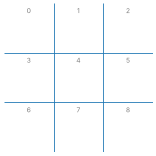

eval for x: (0, False)
eval for o: (0, False)


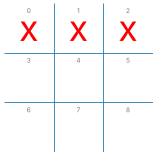

eval for x: (1, True)
eval for o: (-1, True)


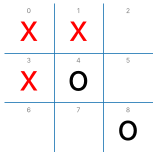

eval for x: (0.8, False)
eval for o: (-0.8, False)


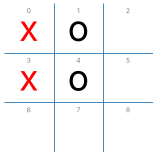

eval for x: (0.0, False)
eval for o: (0.0, False)


In [4]:
board = empty_board() 
show_board(board)
print(f"eval for x: {eval_fun(board)}")
print(f"eval for o: {eval_fun(board, 'o')}")

board = empty_board() 
board[0] = 'x'
board[1] = 'x'
board[2] = 'x' 
show_board(board)
print(f"eval for x: {eval_fun(board)}")
print(f"eval for o: {eval_fun(board, 'o')}")

board = empty_board() 
board[0] = 'x'
board[1] = 'x'
board[3] = 'x' 
board[4] = 'o'
board[8] = 'o'
show_board(board)
print(f"eval for x: {eval_fun(board)}")
print(f"eval for o: {eval_fun(board, 'o')}")

board = empty_board() 
board[0] = 'x'
board[1] = 'o'
board[3] = 'x' 
board[4] = 'o'
show_board(board)
print(f"eval for x: {eval_fun(board)}")
print(f"eval for o: {eval_fun(board, 'o')}")

**Nhận xét – hàm `eval_fun`.** Với trạng thái kết thúc hàm trả về đúng `utility` (±1, 0). Với trạng thái chưa kết thúc nó đếm số *đường 2-trong-1-hàng còn ô thứ ba trống* của mình trừ của đối thủ, nhân 0,4. Vì mỗi người chơi có tối đa 2 đường như vậy nên giá trị luôn nằm trong **[−0,8; +0,8]**, tức là *chặt hơn* khoảng [−1, 1] của trạng thái kết thúc: một thế cờ "có vẻ tốt" không bao giờ được đánh giá cao hơn một chiến thắng thật. Ba bàn cờ đầu tiên cho giá trị 0 (bàn rỗng), +1/−1 (x thắng, tính cho x/o) và 0,8 (x có hai đường đe dọa) đúng như mong đợi.

## Search with Cutoff

We add a cutoff to the Recursive DFS algorithm for Minimax Search with Alpha-Beta Pruning (see AIMA page 156ff). We use the heuristic evaluation function and the back-up the value using minimax search with alpha-beta pruning to determine the next move.

In [5]:
import math

# global variables
DEBUG = 1 # 1 ... count nodes, 2 ... debug each node
COUNT = 0

def alpha_beta_search(board, cutoff = None, player = 'x'):
    """start the search. cutoff = None is minimax search with alpha-beta pruning."""
    global DEBUG, COUNT
    COUNT = 0

    value, move = max_value_ab(board, player, -math.inf, +math.inf, 0, cutoff)
    
    if DEBUG >= 1: print(f"Number of nodes searched (cutoff = {cutoff}): {COUNT}") 
    
    return {"move": move, "value": value}

def max_value_ab(state, player, alpha, beta, depth, cutoff):
    """player's best move."""
    global DEBUG, COUNT
    COUNT += 1
    
    # cut off and terminal test
    v, terminal = eval_fun(state, player)
    if((cutoff is not None and depth >= cutoff) or terminal): 
        if(terminal): 
            alpha, beta = v, v
        if DEBUG >= 2: print(f"stopped at {depth}: {state} term: {terminal} eval: {v} [{alpha}, {beta}]" ) 
        return v, None
    
    v, move = -math.inf, None

    # check all possible actions in the state, update alpha and return move with the largest value
    for a in actions(state):
        v2, a2 = min_value_ab(result(state, player, a), player, alpha, beta, depth + 1, cutoff)
        if v2 > v:
            v, move = v2, a
            alpha = max(alpha, v)
        if v >= beta: return v, move
    
    return v, move

def min_value_ab(state, player, alpha, beta, depth, cutoff):
    """opponent's best response."""
    global DEBUG, COUNT
    COUNT += 1
    
    # cut off and terminal test
    v, terminal = eval_fun(state, player)
    if((cutoff is not None and depth >= cutoff) or terminal): 
        if(terminal): 
            alpha, beta = v, v
        if DEBUG >= 2: print(f"stopped at {depth}: {state} term: {terminal} eval: {v} [{alpha}, {beta}]" ) 
        return v, None
    
    v, move = +math.inf, None

    # check all possible actions in the state, update beta and return move with the smallest value
    for a in actions(state):
        v2, a2 = max_value_ab(result(state, other(player), a), player, alpha, beta, depth + 1, cutoff)
        if v2 < v:
            v, move = v2, a
            beta = min(beta, v)
        if v <= alpha: return v, move
    
    return v, move

## Some Tests

### x is about to win (play 8)

Board:


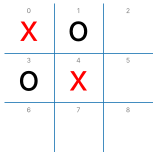


Number of nodes searched (cutoff = 2): 13


{'move': 8, 'value': 1}

CPU times: user 1.59 ms, sys: 217 μs, total: 1.81 ms
Wall time: 2.79 ms

Number of nodes searched (cutoff = 4): 47


{'move': 2, 'value': 1}

CPU times: user 4.5 ms, sys: 59 μs, total: 4.56 ms
Wall time: 14.2 ms

Number of nodes searched (cutoff = None): 61


{'move': 2, 'value': 1}

CPU times: user 6.65 ms, sys: 85 μs, total: 6.73 ms
Wall time: 9.43 ms


In [6]:
board = empty_board() 
board[0] = 'x'
board[1] = 'o'
board[3] = 'o'
board[4] = 'x'

print("Board:")
show_board(board)

print()
%time display(alpha_beta_search(board, 2))

print()
%time display(alpha_beta_search(board, 4))

print()
%time display(alpha_beta_search(board))

**Nhận xét – x sắp thắng.** Ba cấu hình đều cho giá trị +1 và đều chọn nước thắng, nhưng nước đi khác nhau: `cutoff = 2` chọn **ô 8** (thắng ngay trên đường chéo 0-4-8, chỉ 13 nút) còn `cutoff = 4` và tìm kiếm đầy đủ chọn **ô 2** (47 và 61 nút). Với độ sâu 2 thuật toán *không thấy* được thế "song song đe dọa" của ô 2 (ước lượng heuristic chỉ khoảng +0,4) nên ưu tiên ô 8 là nước thắng ngay và đây thật ra là **nước thắng nhanh hơn**; từ độ sâu 4 trở lên cả hai nước đều có giá trị +1 và thuật toán giữ nước đầu tiên theo thứ tự duyệt (ô 2).

### o is about to win

Board:


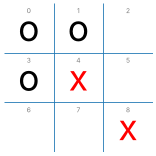


Number of nodes searched (cutoff = 2): 11


{'move': 2, 'value': -1}

CPU times: user 2.5 ms, sys: 0 ns, total: 2.5 ms
Wall time: 2.59 ms

Number of nodes searched (cutoff = None): 15


{'move': 2, 'value': -1}

CPU times: user 2.63 ms, sys: 0 ns, total: 2.63 ms
Wall time: 2.78 ms


In [7]:
board = empty_board() 
board[0] = 'o'
board[1] = 'o'
board[3] = 'o'
board[4] = 'x'
board[8] = 'x'

print("Board:")
show_board(board)

print()
%time display(alpha_beta_search(board, 2))
print()
%time display(alpha_beta_search(board))

**Nhận xét – o sắp thắng.** o có hai đe dọa cùng lúc (ô 2 và ô 6) nên x thua dù đi nước nào. Thế thua này nằm trong tầm nhìn 2 nước nên `cutoff = 2` đã thấy giá trị −1 chỉ với 11 nút (đầy đủ cần 15 nút) và chọn cùng nước đi (ô 2).

### x can draw if it chooses 7

Board:


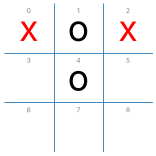


Number of nodes searched (cutoff = 2): 21


{'move': 7, 'value': -0.4}

CPU times: user 3.84 ms, sys: 0 ns, total: 3.84 ms
Wall time: 3.89 ms

Number of nodes searched (cutoff = 4): 81


{'move': 7, 'value': 0}

CPU times: user 11.8 ms, sys: 0 ns, total: 11.8 ms
Wall time: 11.8 ms



Number of nodes searched (cutoff = None): 101


{'move': 7, 'value': 0}

CPU times: user 12 ms, sys: 0 ns, total: 12 ms
Wall time: 12.1 ms


In [8]:
board = empty_board() 
board[0] = 'x'
board[1] = 'o'
board[2] = 'x'
board[4] = 'o'

print("Board:")
show_board(board)

print()
%time display(alpha_beta_search(board, 2))
print()
%time display(alpha_beta_search(board, 4))
print()
%time display(alpha_beta_search(board))

**Nhận xét – x cần tìm đường hòa.** Cả ba cấu hình đều chọn đúng **ô 7** (nước duy nhất không thua). Điểm khác nằm ở *giá trị*: `cutoff = 2` cho −0,4 – chỉ là ước lượng heuristic (o có một đe dọa còn x chưa có) – còn từ `cutoff = 4` giá trị đã là 0, đúng bằng giá trị Minimax. Số nút tăng 21 → 81 → 101: ở thế cờ nhỏ này độ sâu 4 gần như bằng tìm kiếm đầy đủ.

### Empty board: Only a draw an be guaranteed

Board:


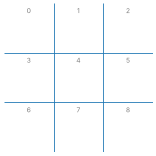


Number of nodes searched (cutoff = 2): 26


{'move': 0, 'value': 0}

CPU times: user 4.51 ms, sys: 0 ns, total: 4.51 ms
Wall time: 4.56 ms



Number of nodes searched (cutoff = 4): 541


{'move': 4, 'value': 0.0}

CPU times: user 75.9 ms, sys: 4 ms, total: 80 ms
Wall time: 81.6 ms



Number of nodes searched (cutoff = None): 18297


{'move': 0, 'value': 0}

CPU times: user 1.19 s, sys: 0 ns, total: 1.19 s
Wall time: 1.21 s


In [9]:
board = empty_board() 

print("Board:")
show_board(board)


print()
%time display(alpha_beta_search(board, 2))
print()
%time display(alpha_beta_search(board, 4))
print()
%time display(alpha_beta_search(board))

**Nhận xét – bàn cờ rỗng (thế cờ lớn nhất).** Đây là nơi cắt độ sâu có lợi nhất: `cutoff = 2` chỉ cần **26 nút**, `cutoff = 4` cần **541 nút** còn tìm kiếm đầy đủ cần **18.297 nút** (nhiều hơn khoảng 700 lần so với cutoff 2). Cả ba đều cho giá trị 0 (hòa) và các nước đi đầu (ô 0 hoặc ô 4) đều là nước không thua. Số nút tăng gần như *theo cấp số nhân* khi tăng độ sâu, vì vậy với trò chơi lớn chỉ có thể dùng độ sâu nhỏ.

### A bad situation

Board:


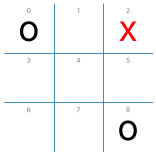


Number of nodes searched (cutoff = 2): 29


{'move': 4, 'value': -0.8}

CPU times: user 4.11 ms, sys: 0 ns, total: 4.11 ms
Wall time: 5.35 ms

Number of nodes searched (cutoff = 4): 148


{'move': 1, 'value': -1}

CPU times: user 15.8 ms, sys: 0 ns, total: 15.8 ms
Wall time: 16.4 ms

Number of nodes searched (cutoff = None): 238


{'move': 1, 'value': -1}

CPU times: user 23.4 ms, sys: 0 ns, total: 23.4 ms
Wall time: 25.5 ms


In [10]:
board = empty_board() 
board[0] = 'o'
board[2] = 'x'
board[8] = 'o'

print("Board:")
show_board(board)

print()
%time display(alpha_beta_search(board, 2))
print()
%time display(alpha_beta_search(board, 4))
print()
%time display(alpha_beta_search(board))

**Nhận xét – tình huống bất lợi.** Đây là thế cờ **đã thua** (giá trị −1): `cutoff = 2` chọn ô 4 với ước lượng −0,8 (lạc quan vì chưa thấy hết cái bẫy của o), trong khi `cutoff = 4` và tìm kiếm đầy đủ nhận ra giá trị thật −1 và chọn ô 1. Về mặt lý thuyết mọi nước đi đều dẫn tới thua nên cả hai nước đều "không tệ hơn" nhau; tuy nhiên điều đáng chú ý là **giá trị ước lượng của cutoff nông không đáng tin cậy** ở các thế cờ có cạm bẫy sâu hơn độ sâu cắt (hiệu ứng *đường chân trời*).

## Experiments



### Minimax with Alpha-Beta Pruning vs. Random

In [11]:
def heuristic2_player(board, player = 'x'):
    return alpha_beta_search(board, cutoff = 2, player = player)["move"]

def heuristic4_player(board, player = 'x'):
    return alpha_beta_search(board, cutoff = 4, player = player)["move"]

def alpha_beta_player(board, player = 'x'):
    return alpha_beta_search(board, cutoff = None, player = player)["move"]

DEBUG = 1
print("heuristic2 vs. random:")
display(play(heuristic2_player, random_player, N = 3))

heuristic2 vs. random:
Number of nodes searched (cutoff = 2): 26
Number of nodes searched (cutoff = 2): 27
Number of nodes searched (cutoff = 2): 10
Number of nodes searched (cutoff = 2): 26
Number of nodes searched (cutoff = 2): 27
Number of nodes searched (cutoff = 2): 10
Number of nodes searched (cutoff = 2): 26
Number of nodes searched (cutoff = 2): 37
Number of nodes searched (cutoff = 2): 10


{'x': 3, 'o': 0, 'd': 0}

In [12]:
DEBUG = 0
print("heuristic2 vs. random:")
%time display(play(heuristic2_player, random_player))

print("heuristic4 vs. random:")
%time display(play(heuristic4_player, random_player))

print()
print("random vs. heuristic2")
%time display(play(random_player, heuristic2_player))

print("random vs. heuristic4")
%time display(play(random_player, heuristic4_player))

heuristic2 vs. random:


{'x': 96, 'o': 0, 'd': 4}

CPU times: user 557 ms, sys: 0 ns, total: 557 ms
Wall time: 560 ms
heuristic4 vs. random:


{'x': 99, 'o': 0, 'd': 1}

CPU times: user 6.67 s, sys: 3.14 ms, total: 6.67 s
Wall time: 6.78 s

random vs. heuristic2


{'x': 4, 'o': 83, 'd': 13}

CPU times: user 454 ms, sys: 0 ns, total: 454 ms
Wall time: 456 ms
random vs. heuristic4


{'x': 0, 'o': 79, 'd': 21}

CPU times: user 3.52 s, sys: 0 ns, total: 3.52 s
Wall time: 3.53 s


**Nhận xét – Heuristic vs. Random (100 ván mỗi chiều).** Cả hai tác tử thắng gần hết khi đi trước (khoảng 95% trở lên) và hòa số còn lại. Khi đi sau có khác biệt: `heuristic4_player` hầu như không thua, còn `heuristic2_player` thỉnh thoảng **thua vài ván** (khoảng 1–3 ván trên 100 ở các lần chạy) vì độ sâu 2 không nhìn thấy các bẫy sâu hơn 2 nước. Đổi lại `heuristic2` chạy nhanh hơn `heuristic4` khoảng 10 lần (xem thời gian ở các ô trên). Với đối thủ ngẫu nhiên yếu, độ sâu 2 đã đủ để thắng áp đảo; chênh lệch chất lượng lộ rõ hơn khi gặp đối thủ mạnh (xem ô tiếp theo).

### Heuristic vs. Minimax with Alpha-Beta Pruning

In [13]:
DEBUG = 0

# Note: No randomness -> play only once

print("heuristic2 vs. alpha_beta")
%time display(play(heuristic2_player, alpha_beta_player, N = 1))

print()
print("alpha_beta vs. heuristic2")
%time display(play(alpha_beta_player, heuristic2_player, N = 1))

print()
print("heuristic4 vs alpha_beta")
%time display(play(heuristic4_player, alpha_beta_player, N = 1))

print()
print("alpha_beta vs. heuristic4")
%time display(play(alpha_beta_player, heuristic4_player, N = 1))

heuristic2 vs. alpha_beta


{'x': 0, 'o': 0, 'd': 1}

CPU times: user 126 ms, sys: 200 μs, total: 126 ms
Wall time: 128 ms

alpha_beta vs. heuristic2


{'x': 1, 'o': 0, 'd': 0}

CPU times: user 959 ms, sys: 0 ns, total: 959 ms
Wall time: 967 ms

heuristic4 vs alpha_beta


{'x': 0, 'o': 0, 'd': 1}

CPU times: user 181 ms, sys: 0 ns, total: 181 ms
Wall time: 184 ms

alpha_beta vs. heuristic4


{'x': 0, 'o': 0, 'd': 1}

CPU times: user 974 ms, sys: 0 ns, total: 974 ms
Wall time: 1.02 s


**Nhận xét – Heuristic vs. Alpha-Beta đầy đủ** (các ván đều tất định nên mỗi chiều chỉ cần chạy một lần):

* `heuristic4` **hòa** với Alpha-Beta ở cả hai chiều;
* `heuristic2` hòa khi đi trước nhưng **thua** khi đi sau (ván "alpha_beta vs. heuristic2" do Alpha-Beta thắng): độ sâu 2 không nhìn thấy các cạm bẫy của đối thủ chơi tối ưu;
* Vậy với đối thủ mạnh, chất lượng nước đi của heuristic phụ thuộc rõ vào độ sâu: độ sâu 4 đủ để giữ hòa trong Tic-Tac-Toe còn độ sâu 2 thì chưa. Đổi lại cả hai dùng ít nút và ít thời gian hơn rất nhiều so với Alpha-Beta đầy đủ.

### Heuristic vs. Heuristic

In [14]:
DEBUG = 0

# Note: No randomness -> play only once

print("heuristic2 vs. heuristic4")
%time display(play(heuristic2_player, heuristic4_player, N = 1))

print()
print("heuristic4 vs. heuristic2")
%time display(play(heuristic4_player, heuristic2_player, N = 1))

heuristic2 vs. heuristic4


{'x': 0, 'o': 0, 'd': 1}

CPU times: user 31.6 ms, sys: 0 ns, total: 31.6 ms
Wall time: 32.8 ms

heuristic4 vs. heuristic2


{'x': 0, 'o': 0, 'd': 1}

CPU times: user 62.3 ms, sys: 0 ns, total: 62.3 ms
Wall time: 64.2 ms


**Nhận xét – Heuristic vs. Heuristic.** Hai tác tử cùng chơi tất định (không có yếu tố ngẫu nhiên) nên chỉ cần chạy 1 ván mỗi chiều; cả hai chiều đều kết thúc **hòa**, phù hợp với giá trị lý thuyết của Tic-Tac-Toe.

__Idea:__ Start experiments with different boards that already have a few x's and o's randomly placed on them.

---
# Lab 05 – Bài 4: Thực hành bổ sung (bảng so sánh Alpha-Beta đầy đủ và Heuristic Alpha-Beta với cutoff = 2, 4)

> Các ô phía trên là nội dung gốc của giảng viên (giữ nguyên). Phần dưới chạy **cùng 5 trạng thái kiểm thử của Bài 3**,
> đo *nước đi, giá trị, số nút, thời gian* và đánh giá **chất lượng nước đi** bằng một bộ giải Minimax chính xác độc lập (có nhớ kết quả).

In [15]:
import time
import random
from functools import lru_cache
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tictactoe
from tictactoe import check_board, other
from IPython.display import Markdown

DEBUG = 0

def make_board(**cells):
    b = empty_board()
    for symbol, idx in cells.items():
        for i in idx: b[i] = symbol
    return b

TESTS = {
    "X sắp thắng"         : make_board(x=[0, 4], o=[1, 3]),
    "X cần tìm đường hòa" : make_board(x=[0, 2], o=[1, 4]),
    "Tình huống bất lợi"  : make_board(x=[2], o=[0, 8]),
    "O sắp thắng"         : make_board(x=[4, 8], o=[0, 1, 3]),
    "Bàn cờ rỗng"         : empty_board(),
}

# ---- Bộ giải Minimax chính xác (độc lập với các hàm tìm kiếm ở trên) để đánh giá chất lượng nước đi ----
@lru_cache(maxsize=None)
def solve(state, mover):
    """giá trị Minimax chính xác theo góc nhìn của x: x thắng = +1, o thắng = -1, hòa = 0"""
    g = check_board(list(state))
    if g == 'x': return 1
    if g == 'o': return -1
    if g == 'd': return 0
    vals = []
    for a in tictactoe.actions(list(state)):
        c = list(state); c[a] = mover
        vals.append(solve(tuple(c), other(mover)))
    return max(vals) if mover == 'x' else min(vals)

def action_values(b, mover = 'x'):
    """giá trị chính xác (theo góc nhìn của người đi) của từng nước đi"""
    sign = 1 if mover == 'x' else -1
    out = {}
    for a in tictactoe.actions(b):
        c = list(b); c[a] = mover
        out[a] = sign * solve(tuple(c), other(mover))
    return out

def run(b, cutoff, mover = 'x'):
    t0 = time.perf_counter()
    r = alpha_beta_search(b, cutoff, mover)
    ms = (time.perf_counter() - t0) * 1000
    return r["move"], r["value"], COUNT, ms

CONFIGS = [("Alpha-Beta đầy đủ", "-", None), ("Heuristic Alpha-Beta", "cutoff = 2", 2), ("Heuristic Alpha-Beta", "cutoff = 4", 4)]

rows = []
for name, b in TESTS.items():
    av = action_values(b)
    best = max(av.values())
    for method, cfg, cutoff in CONFIGS:
        move, value, nodes, ms = run(b, cutoff)
        rows.append({"Trạng thái": name, "Phương pháp": method, "Độ sâu/cấu hình": cfg,
                     "Nước đi": move, "Giá trị tìm được": round(value, 2),
                     "Giá trị thật của nước đi": av[move], "Số nút": nodes, "Thời gian (ms)": round(ms, 2),
                     "Nước tối ưu?": "có" if av[move] == best else "KHÔNG"})
res_table = pd.DataFrame(rows)
for name in TESTS:
    print(f"=== {name} ===")
    display(res_table[res_table["Trạng thái"] == name].drop(columns = "Trạng thái").reset_index(drop = True))

=== X sắp thắng ===


,Phương pháp,Độ sâu/cấu hình,Nước đi,Giá trị tìm được,Giá trị thật của nước đi,Số nút,Thời gian (ms),Nước tối ưu?
0,Alpha-Beta đầy đủ,-,2,1.0,1,61,3.22,có
1,Heuristic Alpha-Beta,cutoff = 2,8,1.0,1,13,0.88,có
2,Heuristic Alpha-Beta,cutoff = 4,2,1.0,1,47,2.96,có


=== X cần tìm đường hòa ===


,Phương pháp,Độ sâu/cấu hình,Nước đi,Giá trị tìm được,Giá trị thật của nước đi,Số nút,Thời gian (ms),Nước tối ưu?
0,Alpha-Beta đầy đủ,-,7,0.0,0,101,4.80,có
1,Heuristic Alpha-Beta,cutoff = 2,7,-0.4,0,21,1.36,có
2,Heuristic Alpha-Beta,cutoff = 4,7,0.0,0,81,4.75,có


=== Tình huống bất lợi ===


,Phương pháp,Độ sâu/cấu hình,Nước đi,Giá trị tìm được,Giá trị thật của nước đi,Số nút,Thời gian (ms),Nước tối ưu?
0,Alpha-Beta đầy đủ,-,1,-1.0,-1,238,11.63,có
1,Heuristic Alpha-Beta,cutoff = 2,4,-0.8,-1,29,1.99,có
2,Heuristic Alpha-Beta,cutoff = 4,1,-1.0,-1,148,8.53,có


=== O sắp thắng ===


,Phương pháp,Độ sâu/cấu hình,Nước đi,Giá trị tìm được,Giá trị thật của nước đi,Số nút,Thời gian (ms),Nước tối ưu?
0,Alpha-Beta đầy đủ,-,2,-1.0,-1,15,0.72,có
1,Heuristic Alpha-Beta,cutoff = 2,2,-1.0,-1,11,0.56,có
2,Heuristic Alpha-Beta,cutoff = 4,2,-1.0,-1,15,0.65,có


=== Bàn cờ rỗng ===


,Phương pháp,Độ sâu/cấu hình,Nước đi,Giá trị tìm được,Giá trị thật của nước đi,Số nút,Thời gian (ms),Nước tối ưu?
0,Alpha-Beta đầy đủ,-,0,0.0,0,18297,934.32,có
1,Heuristic Alpha-Beta,cutoff = 2,0,0.0,0,26,1.79,có
2,Heuristic Alpha-Beta,cutoff = 4,4,0.0,0,541,44.67,có


In [16]:
# Tổng hợp theo cấu hình trên 5 trạng thái kiểm thử
summary = (res_table.assign(Cấu_hình = res_table["Phương pháp"] + " (" + res_table["Độ sâu/cấu hình"] + ")")
           .groupby("Cấu_hình", sort = False)
           .agg(Tổng_số_nút = ("Số nút", "sum"), Tổng_thời_gian_ms = ("Thời gian (ms)", "sum"),
                Số_nước_tối_ưu = ("Nước tối ưu?", lambda s: (s == "có").sum())))
summary["Tổng_thời_gian_ms"] = summary["Tổng_thời_gian_ms"].round(1)
display(summary)

,Tổng_số_nút,Tổng_thời_gian_ms,Số_nước_tối_ưu
Cấu_hình,,,
Alpha-Beta đầy đủ (-),18712,954.7,5
Heuristic Alpha-Beta (cutoff = 2),100,6.6,5
Heuristic Alpha-Beta (cutoff = 4),832,61.6,5


## Độ sâu cắt ảnh hưởng thế nào tới chất lượng và chi phí?

Ta thay đổi `cutoff` từ 1 đến 6 (và tìm kiếm đầy đủ) trên **400 thế cờ ngẫu nhiên** đạt được trong ván đấu (mọi giai đoạn của ván) và đo:
* *chất lượng*: tỉ lệ thế cờ mà nước đi được chọn là **nước tối ưu** (so với bộ giải chính xác);
* *chi phí*: số nút trung bình và thời gian trung bình mỗi quyết định; riêng bàn cờ rỗng đo số nút theo cutoff.

Có 4,520 thế cờ chưa kết thúc; lấy mẫu ngẫu nhiên 400 thế (seed cố định).


,cutoff,% nước tối ưu,Số nút TB / quyết định,Thời gian TB (ms)
0,1,93.25,4.50,0.29
1,2,97.50,10.14,0.62
2,3,97.00,20.69,1.22
3,4,100.00,32.93,1.92
4,5,99.75,42.18,2.38
5,6,100.00,48.04,2.50
6,Đầy đủ,100.00,51.64,2.65


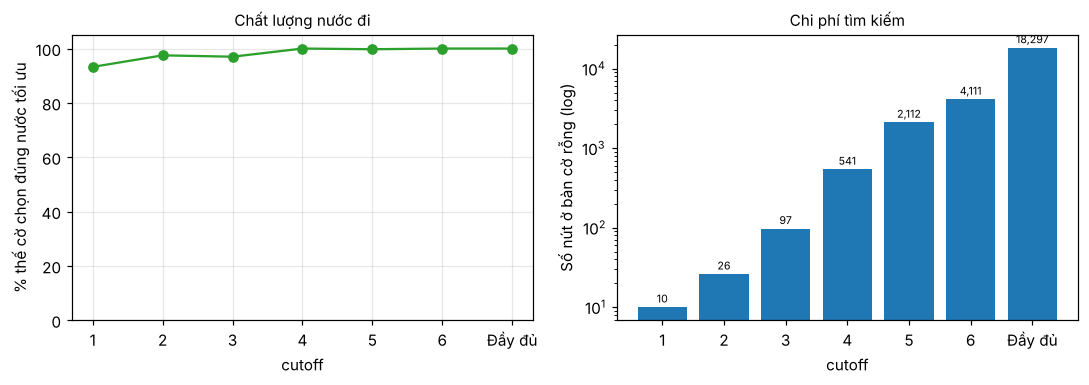

In [17]:
# Tập thế cờ chưa kết thúc đạt được từ bàn cờ rỗng
start = tuple(empty_board())
reach, frontier = {start: 'x'}, [(start, 'x')]
while frontier:
    nxt = []
    for s, p in frontier:
        if check_board(list(s)) != 'n': continue
        for a in tictactoe.actions(list(s)):
            c = list(s); c[a] = p; c = tuple(c)
            if c not in reach:
                reach[c] = other(p); nxt.append((c, other(p)))
    frontier = nxt
nonterminal = [(list(s), p) for s, p in reach.items() if check_board(list(s)) == 'n']
print(f"Có {len(nonterminal):,} thế cờ chưa kết thúc; lấy mẫu ngẫu nhiên 400 thế (seed cố định).")
sample = random.Random(2026).sample(nonterminal, 400)

CUTOFFS = [1, 2, 3, 4, 5, 6, None]
stat = {c: {"opt": 0, "nodes": 0, "ms": 0.0} for c in CUTOFFS}
for b, mover in sample:
    av = action_values(b, mover)
    best = max(av.values())
    for c in CUTOFFS:
        move, value, nodes, ms = run(b, c, mover)
        stat[c]["opt"] += (av[move] == best); stat[c]["nodes"] += nodes; stat[c]["ms"] += ms

q = pd.DataFrame({"cutoff": ["Đầy đủ" if c is None else c for c in CUTOFFS],
                  "% nước tối ưu": [100 * stat[c]["opt"] / len(sample) for c in CUTOFFS],
                  "Số nút TB / quyết định": [stat[c]["nodes"] / len(sample) for c in CUTOFFS],
                  "Thời gian TB (ms)": [stat[c]["ms"] / len(sample) for c in CUTOFFS]}).round(2)
display(q)

# số nút theo cutoff trên bàn cờ rỗng
empty_nodes = [run(empty_board(), c)[2] for c in CUTOFFS]

fig, ax = plt.subplots(1, 2, figsize = (10, 3.6), dpi = 110)
labels = [str(c) if c else "Đầy đủ" for c in CUTOFFS]
ax[0].plot(labels, q["% nước tối ưu"], marker = "o", color = "#2ca02c")
ax[0].set_ylabel("% thế cờ chọn đúng nước tối ưu"); ax[0].set_xlabel("cutoff"); ax[0].set_ylim(0, 105)
ax[0].set_title("Chất lượng nước đi", fontsize = 10); ax[0].grid(alpha = .3)
ax[1].bar(labels, empty_nodes, color = "#1f77b4"); ax[1].set_yscale("log")
for i, v in enumerate(empty_nodes): ax[1].text(i, v * 1.15, f"{v:,}", ha = "center", fontsize = 7)
ax[1].set_ylabel("Số nút ở bàn cờ rỗng (log)"); ax[1].set_xlabel("cutoff"); ax[1].set_title("Chi phí tìm kiếm", fontsize = 10)
plt.tight_layout(); plt.show()

**Nhận xét – đánh đổi giữa độ sâu và chất lượng quyết định.**

* **Chi phí tăng rất nhanh theo độ sâu**: ở bàn cờ rỗng, số nút tăng gần như theo cấp số nhân (xem biểu đồ bên phải); tìm kiếm đầy đủ cần hàng chục nghìn nút trong khi `cutoff = 2` chỉ vài chục nút.
* **Chất lượng tăng nhanh rồi bão hòa**: tỉ lệ chọn nước tối ưu ở độ sâu nông thấp hơn rõ rệt và đạt mức 100% khi độ sâu đủ lớn để nhìn thấy mọi đòn chiến thuật (xem bảng và biểu đồ bên trái). Độ sâu lớn hơn một ngưỡng nào đó không còn cải thiện chất lượng mà chỉ tốn thêm thời gian.
* **Hàm heuristic bù lại một phần cho độ sâu nông**, nhưng giá trị ước lượng chỉ đáng tin khi thế cờ *yên tĩnh*; ở thế có cạm bẫy sâu hơn độ sâu cắt (như "tình huống bất lợi") giá trị bị lạc quan (−0,8 thay vì −1).
* **Khi nào dùng heuristic + cutoff?** Khi cây trò chơi quá lớn để duyệt tới trạng thái kết thúc (Connect 4, cờ vua...) và ta có một hàm đánh giá hợp lý; với Tic-Tac-Toe chỉ nhằm mục đích minh họa vì Alpha-Beta đầy đủ vẫn chạy được trong vài giây.